# NEU Steel Surface Defect Classification
## Classical machine learning, stratified 5-fold CV, and model selection (CPU)

**Research question:** Which classical ML classifier performs best on the six-class NEU steel-surface defect problem using 64×64 HOG, LBP, and intensity features?

## Load and validate cached training features

In [1]:
from pathlib import Path
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from threadpoolctl import threadpool_limits

root_hint = os.getenv('NEU_PROJECT_ROOT')
candidates_roots = ([Path(root_hint).expanduser()] if root_hint else []) + [
    Path.home() / 'base' / 'NEU_Steel_Defects_CPU',
    Path.cwd(), *Path.cwd().parents,
]
ROOT = next((p.resolve() for p in candidates_roots
             if (p / 'outputs' / 'step3_train_features.npz').is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        'Cannot find outputs/step3_train_features.npz. Run Step 3 first, '
        'or set NEU_PROJECT_ROOT to the project folder.'
    )
OUT = ROOT / 'outputs'
input_path = OUT / 'step3_train_features.npz'
# Step 3 stores pandas string labels as an object array; load only your own locally generated NPZ.
with np.load(input_path, allow_pickle=True) as data:
    X = np.asarray(data['X'], dtype=np.float32)
    y = np.asarray(data['y']).astype(str)
    feature_group_sizes = np.asarray(data['feature_group_sizes']).astype(int).tolist()
summary_path = OUT / 'step3_feature_summary.json'
meta = json.loads(summary_path.read_text(encoding='utf-8'))

assert X.ndim == 2 and len(X) == len(y) and X.shape[1] > 10
assert np.isfinite(X).all(), 'The feature matrix contains NaN/Inf; stop and investigate.'
assert X.shape[0] == meta['train_after_dedup'], 'Training-row count differs from Step 3 metadata.'
assert X.shape[1] == meta['feature_count'], 'Feature count differs from Step 3 metadata.'
assert sum(feature_group_sizes) == X.shape[1]
assert meta['heldout_test_count'] == 360, 'Unexpected held-out dataset description.'
classes, counts = np.unique(y, return_counts=True)
assert len(classes) == 6 and counts.min() >= 5

print('Project:', ROOT)
print('Training features:', X.shape, '| dtype:', X.dtype)
print('Feature groups [HOG, LBP, stats]:', feature_group_sizes)
print('Classes:', dict(zip(classes.tolist(), counts.tolist())))
print('Held-out test images RESERVED, NOT LOADED:', meta['heldout_test_count'])

Project: /home/eren/base/NEU_Steel_Defects_CPU
Training features: (1439, 1786) | dtype: float32
Feature groups [HOG, LBP, stats]: [1764, 10, 12]
Classes: {'crazing': 240, 'inclusion': 240, 'patches': 239, 'pitted_surface': 240, 'rolled-in_scale': 240, 'scratches': 240}
Held-out test images RESERVED, NOT LOADED: 360


## Define the experimental protocol

- **Primary selection metric:** mean *macro-F1* over five stratified folds. Macro-F1 gives each class equal importance.
- **Additional metrics:** accuracy, balanced accuracy, macro-precision, macro-recall.
- **Same folds for all candidates:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
- **Parameter search:** two CPU-conscious settings per classifier, plus no-PCA baselines for k-NN and SVM. These are predefined candidates, not an exhaustive search.
- **Preprocessing:** StandardScaler + PCA for Gaussian NB, k-NN and SVM. Tree models use the unscaled original 1,786-dimensional feature vectors.


In [10]:
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
    'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
    'f1_macro': make_scorer(f1_score, average='macro', zero_division=0),
}
# Set to True only if you need a quicker exploratory run. Keep False for the final homework!
FAST_MODE = False
print('CV folds:', CV.n_splits, '| Fast mode:', FAST_MODE)

CV folds: 5 | Fast mode: False


## Configure all five classifiers (12 candidates in total)

In [3]:
# Pipeline fitting occurs independently inside every CV training fold.
# Explicit random_state values make the comparisons reproducible.
def pca_steps(n_components):
    return [
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components, svd_solver='randomized',
                    random_state=RANDOM_STATE)),
    ]

CANDIDATES = [
    {'algorithm': 'Gaussian Naive Bayes', 'config': 'PCA64_smooth1e-8',
     'estimator': Pipeline(pca_steps(64) + [('clf', GaussianNB(var_smoothing=1e-8))])},
    {'algorithm': 'Gaussian Naive Bayes', 'config': 'PCA128_smooth1e-9',
     'estimator': Pipeline(pca_steps(128) + [('clf', GaussianNB(var_smoothing=1e-9))])},

    {'algorithm': 'Decision Tree', 'config': 'depth12_leaf3',
     'estimator': Pipeline([('clf', DecisionTreeClassifier(
         max_depth=12, min_samples_leaf=3, random_state=RANDOM_STATE))])},
    {'algorithm': 'Decision Tree', 'config': 'depthNone_leaf5',
     'estimator': Pipeline([('clf', DecisionTreeClassifier(
         max_depth=None, min_samples_leaf=5, random_state=RANDOM_STATE))])},

    {'algorithm': 'k-Nearest Neighbors', 'config': 'PCA64_k5_distance',
     'estimator': Pipeline(pca_steps(64) + [('clf', KNeighborsClassifier(
         n_neighbors=5, weights='distance', n_jobs=2))])},
    {'algorithm': 'k-Nearest Neighbors', 'config': 'PCA128_k11_distance',
     'estimator': Pipeline(pca_steps(128) + [('clf', KNeighborsClassifier(
         n_neighbors=11, weights='distance', n_jobs=2))])},
    {'algorithm': 'k-Nearest Neighbors', 'config': 'NoPCA_k5_distance',
     'estimator': Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(
         n_neighbors=5, weights='distance', n_jobs=2))])},

    {'algorithm': 'SVM (RBF)', 'config': 'PCA64_C1',
     'estimator': Pipeline(pca_steps(64) + [('clf', SVC(
         kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_STATE))])},
    {'algorithm': 'SVM (RBF)', 'config': 'PCA128_C3',
     'estimator': Pipeline(pca_steps(128) + [('clf', SVC(
         kernel='rbf', C=3.0, gamma='scale', random_state=RANDOM_STATE))])},
    {'algorithm': 'SVM (RBF)', 'config': 'NoPCA_C3',
     'estimator': Pipeline([('scaler', StandardScaler()), ('clf', SVC(
         kernel='rbf', C=3.0, gamma='scale', random_state=RANDOM_STATE))])},

    {'algorithm': 'Random Forest', 'config': 'trees120_leaf1',
     'estimator': Pipeline([('clf', RandomForestClassifier(
         n_estimators=120, min_samples_leaf=1, max_features='sqrt',
         random_state=RANDOM_STATE, n_jobs=2))])},
    {'algorithm': 'Random Forest', 'config': 'trees180_leaf3',
     'estimator': Pipeline([('clf', RandomForestClassifier(
         n_estimators=180, min_samples_leaf=3, max_features='sqrt',
         random_state=RANDOM_STATE, n_jobs=2))])},
]

if FAST_MODE:
    # Temporary CPU diagnostic only; NEVER interpret FAST_MODE results as final tuned comparison.
    seen = set()
    reduced = []
    for c in CANDIDATES:
        if c['algorithm'] not in seen:
            seen.add(c['algorithm'])
            reduced.append(c)
    CANDIDATES = reduced
    print('WARNING: FAST_MODE uses only one candidate per model.')

assert len({c['algorithm'] for c in CANDIDATES}) == 5
print(f'Configured {len(CANDIDATES)} model candidates:')
display(pd.DataFrame([{'Algorithm': c['algorithm'], 'Configuration': c['config']}
                      for c in CANDIDATES]))

Configured 12 model candidates:


,Algorithm,Configuration
0,Gaussian Naive Bayes,PCA64_smooth1e-8
1,Gaussian Naive Bayes,PCA128_smooth1e-9
2,Decision Tree,depth12_leaf3
3,Decision Tree,depthNone_leaf5
4,k-Nearest Neighbors,PCA64_k5_distance
5,k-Nearest Neighbors,PCA128_k11_distance
6,k-Nearest Neighbors,NoPCA_k5_distance
7,SVM (RBF),PCA64_C1
8,SVM (RBF),PCA128_C3
9,SVM (RBF),NoPCA_C3


## Run stratified cross-validation (training data ONLY)

All scores are computed on held-out **CV validation folds within the training split**. No image in the NEU `validation/` directory is accessed here.


In [4]:
fold_rows = []
start_time = time.perf_counter()
with threadpool_limits(limits=2):
    for index, candidate in enumerate(CANDIDATES, start=1):
        label = f"{candidate['algorithm']} / {candidate['config']}"
        t0 = time.perf_counter()
        scores = cross_validate(
            estimator=candidate['estimator'], X=X, y=y, cv=CV,
            scoring=SCORING, return_train_score=False,
            n_jobs=1, error_score='raise',
        )
        for fold in range(CV.n_splits):
            row = {
                'algorithm': candidate['algorithm'],
                'config': candidate['config'],
                'fold': fold + 1,
            }
            row.update({metric: float(scores['test_' + metric][fold])
                        for metric in SCORING})
            row['fit_seconds'] = float(scores['fit_time'][fold])
            fold_rows.append(row)
        print(f"[{index:02d}/{len(CANDIDATES)}] {label}: "
              f"macro-F1={scores['test_f1_macro'].mean():.4f} "
              f"(+/- {scores['test_f1_macro'].std():.4f}); "
              f"elapsed={time.perf_counter()-t0:.1f}s", flush=True)

cv_folds = pd.DataFrame(fold_rows)
assert len(cv_folds) == len(CANDIDATES) * CV.n_splits
cv_folds.to_csv(OUT / 'step4_cv_fold_scores.csv', index=False)
print(f'CV FINISHED — elapsed {time.perf_counter()-start_time:.1f}s')
print('Saved:', OUT / 'step4_cv_fold_scores.csv')

[01/12] Gaussian Naive Bayes / PCA64_smooth1e-8: macro-F1=0.7818 (+/- 0.0130); elapsed=0.5s
[02/12] Gaussian Naive Bayes / PCA128_smooth1e-9: macro-F1=0.7604 (+/- 0.0172); elapsed=0.4s
[03/12] Decision Tree / depth12_leaf3: macro-F1=0.8971 (+/- 0.0098); elapsed=3.6s
[04/12] Decision Tree / depthNone_leaf5: macro-F1=0.9091 (+/- 0.0175); elapsed=3.4s
[05/12] k-Nearest Neighbors / PCA64_k5_distance: macro-F1=0.6148 (+/- 0.0205); elapsed=0.4s
[06/12] k-Nearest Neighbors / PCA128_k11_distance: macro-F1=0.5472 (+/- 0.0088); elapsed=0.4s
[07/12] k-Nearest Neighbors / NoPCA_k5_distance: macro-F1=0.5465 (+/- 0.0138); elapsed=0.3s
[08/12] SVM (RBF) / PCA64_C1: macro-F1=0.8636 (+/- 0.0218); elapsed=0.6s
[09/12] SVM (RBF) / PCA128_C3: macro-F1=0.8629 (+/- 0.0166); elapsed=0.7s
[10/12] SVM (RBF) / NoPCA_C3: macro-F1=0.9143 (+/- 0.0094); elapsed=3.1s
[11/12] Random Forest / trees120_leaf1: macro-F1=0.9415 (+/- 0.0089); elapsed=5.5s
[12/12] Random Forest / trees180_leaf3: macro-F1=0.9416 (+/- 0.0109)

## Summarize candidates and choose the best configuration

In [5]:
metric_columns = list(SCORING)
agg_spec = {
    f'{m}_mean': (m, 'mean') for m in metric_columns
}
agg_spec.update({f'{m}_std': (m, 'std') for m in metric_columns})
agg_spec['total_fit_seconds'] = ('fit_seconds', 'sum')
cv_summary = (cv_folds.groupby(['algorithm', 'config'], as_index=False)
              .agg(**agg_spec)
              .sort_values(['f1_macro_mean', 'accuracy_mean', 'algorithm'],
                           ascending=[False, False, True])
              .reset_index(drop=True))
cv_summary.insert(0, 'overall_rank', np.arange(1, len(cv_summary) + 1))
cv_summary.to_csv(OUT / 'step4_cv_all_candidates.csv', index=False)

# Best candidate of EACH algorithm, for the side-by-side teacher comparison.
best_by_algorithm = (cv_summary.sort_values(
    ['f1_macro_mean', 'accuracy_mean'], ascending=[False, False])
    .drop_duplicates('algorithm')
    .sort_values('f1_macro_mean', ascending=False)
    .reset_index(drop=True))
best_by_algorithm.to_csv(OUT / 'step4_best_per_algorithm.csv', index=False)

selected = cv_summary.iloc[0]
selected_candidate = next(c for c in CANDIDATES if
    c['algorithm'] == selected['algorithm'] and c['config'] == selected['config'])

cols = ['algorithm', 'config', 'f1_macro_mean', 'f1_macro_std',
        'accuracy_mean', 'balanced_accuracy_mean',
        'precision_macro_mean', 'recall_macro_mean']
print('BEST CONFIGURATION FOR EACH OF THE FIVE ALGORITHMS:')
display(best_by_algorithm[cols].round(4))
print('\nSELECTED BY CV MACRO-F1:', selected['algorithm'], '/', selected['config'])
print('Macro-F1:', round(float(selected['f1_macro_mean']), 4))

BEST CONFIGURATION FOR EACH OF THE FIVE ALGORITHMS:


,algorithm,config,f1_macro_mean,f1_macro_std,accuracy_mean,balanced_accuracy_mean,precision_macro_mean,recall_macro_mean
0,Random Forest,trees180_leaf3,0.9416,0.0122,0.9416,0.9417,0.9435,0.9417
1,SVM (RBF),NoPCA_C3,0.9143,0.0105,0.9152,0.9153,0.9155,0.9153
2,Decision Tree,depthNone_leaf5,0.9091,0.0195,0.9090,0.9090,0.9113,0.9090
3,Gaussian Naive Bayes,PCA64_smooth1e-8,0.7818,0.0145,0.7860,0.7857,0.8101,0.7857
4,k-Nearest Neighbors,PCA64_k5_distance,0.6148,0.0229,0.6526,0.6522,0.7605,0.6522



SELECTED BY CV MACRO-F1: Random Forest / trees180_leaf3
Macro-F1: 0.9416


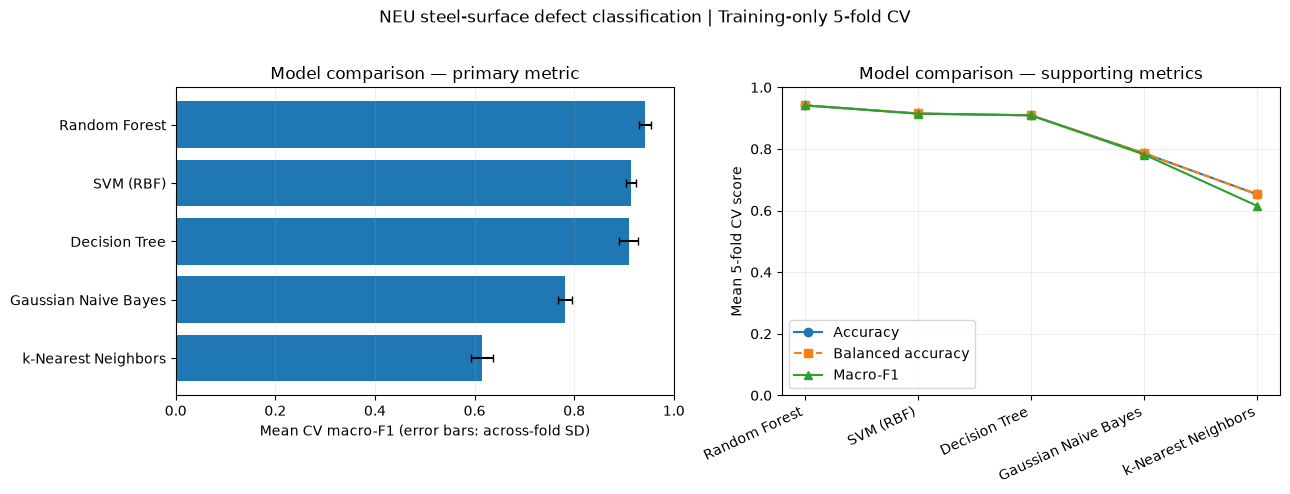

Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step4_cv_model_comparison.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_data = best_by_algorithm.iloc[::-1]
y_pos = np.arange(len(plot_data))
axes[0].barh(y_pos, plot_data['f1_macro_mean'],
             xerr=plot_data['f1_macro_std'], capsize=3)
axes[0].set_yticks(y_pos, plot_data['algorithm'])
axes[0].set_xlim(0, 1)
axes[0].set_xlabel('Mean CV macro-F1 (error bars: across-fold SD)')
axes[0].set_title('Model comparison — primary metric')
axes[0].grid(axis='x', alpha=0.2)

x_pos = np.arange(len(best_by_algorithm))
axes[1].plot(x_pos, best_by_algorithm['accuracy_mean'], 'o-', label='Accuracy')
axes[1].plot(x_pos, best_by_algorithm['balanced_accuracy_mean'], 's--',
             label='Balanced accuracy')
axes[1].plot(x_pos, best_by_algorithm['f1_macro_mean'], '^-', label='Macro-F1')
axes[1].set_xticks(x_pos, best_by_algorithm['algorithm'], rotation=25, ha='right')
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Mean 5-fold CV score')
axes[1].set_title('Model comparison — supporting metrics')
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.suptitle('NEU steel-surface defect classification | Training-only 5-fold CV', y=1.02)
plt.tight_layout()
plot_path = OUT / 'step4_cv_model_comparison.png'
plt.savefig(plot_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', plot_path)

In [ ]:
if FAST_MODE:
    raise RuntimeError('FAST_MODE=True: disable it and rerun the complete CV before saving a final model.')

final_pipeline = clone(selected_candidate['estimator'])
t0 = time.perf_counter()
with threadpool_limits(limits=2):
    final_pipeline.fit(X, y)
model_path = OUT / 'step4_selected_pipeline.joblib'
joblib.dump(final_pipeline, model_path, compress=3)

selection_info = {
    'dataset': meta['dataset'],
    'selected_algorithm': str(selected['algorithm']),
    'selected_configuration': str(selected['config']),
    'selection_metric': 'mean 5-fold stratified CV macro-F1 on training images only',
    'cv_macro_f1_mean': float(selected['f1_macro_mean']),
    'cv_macro_f1_std': float(selected['f1_macro_std']),
    'cv_accuracy_mean': float(selected['accuracy_mean']),
    'cv_balanced_accuracy_mean': float(selected['balanced_accuracy_mean']),
    'cv_folds': int(CV.n_splits),
    'cv_random_state': int(RANDOM_STATE),
    'train_samples': int(X.shape[0]),
    'n_features': int(X.shape[1]),
    'feature_group_sizes': feature_group_sizes,
    'feature_extraction': {
        'image_size': meta['image_size'],
        'hog': meta['hog'],
        'lbp': meta['lbp'],
        'statistics': 'Step 3 12-statistic definition',
    },
    'classes': classes.tolist(),
    'holdout_test_count': int(meta['heldout_test_count']),
    'holdout_evaluated': False,
    'model_file': model_path.name,
    'package_versions': {
        'numpy': np.__version__,
        'scikit_learn': __import__('sklearn').__version__,
    },
}
info_path = OUT / 'step4_selected_model_info.json'
info_path.write_text(json.dumps(selection_info, indent=2), encoding='utf-8')
print('Final train-only refit complete in', round(time.perf_counter()-t0, 1), 'sec')
print('Saved pipeline:', model_path)
print('Saved selection metadata:', info_path)

Final train-only refit complete in 2.2 sec
Saved pipeline: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step4_selected_pipeline.joblib
Saved selection metadata: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step4_selected_model_info.json
STEP 4 COMPLETE — five-fold model selection finished. Test set remains untouched.
